MD# 04 · Pseudobulk differential expression, PD vs control

Pipeline (scripts, not re-run here because they need the count matrices):
1. `analysis/01_pseudobulk.py` sums raw counts per donor × cell type over the 16,345 genes shared by all datasets (sorted libraries and Unresolved nuclei excluded).
2. `analysis/02_pseudobulk_DE.py` runs pydeseq2 per region × cell type with design `~ dataset + condition`, using only datasets that contain both PD and control donors and requiring ≥ 4 donors per group.
3. `analysis/03_DE_figures.py` draws the figures below (executed in this notebook).

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
# Notebooks run from the project root so that results/ and config/ resolve.
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
s = pd.read_csv("results/pseudobulk/DE_summary.csv")
s.sort_values(["region", "DE_padj05"], ascending=[True, False])[["region","cell_type","donors_PD","donors_Ctrl","datasets","genes_tested","DE_padj05","up_in_PD","down_in_PD"]]

,region,cell_type,donors_PD,donors_Ctrl,datasets,genes_tested,DE_padj05,up_in_PD,down_in_PD
7,Cortex,Oligo,18,19,3,7167,3,3,0
6,Cortex,OPC,17,14,3,6524,2,1,1
5,Cortex,Micro_PVM,12,7,2,5608,1,0,1
2,Cortex,Astro,18,15,3,6902,0,0,0
3,Cortex,EN,21,21,3,11691,0,0,0
4,Cortex,IN,20,20,3,8777,0,0,0
11,Midbrain,Oligo,51,62,7,9401,2179,1106,1073
0,Midbrain,Micro_PVM,32,29,7,5169,123,75,48
1,Midbrain,Astro,33,35,6,6965,106,57,49
10,Midbrain,OPC,36,38,6,5746,76,46,30


       gene  n_celltypes  Micro_PVM  Astro  Oligo   OPC
0   ANAPC16            4       0.66   0.75   0.53  0.73
1   SLC38A2            4       0.53   1.21   1.11  0.80
6   CHORDC1            3       1.62   1.71   1.28   NaN
11    CIRBP            3      -0.85  -0.89  -0.80   NaN
8    DNAJA1            3       1.06   1.53   1.03   NaN
10   DNAJB6            3       0.70   0.92   0.67   NaN
2      GAB1            3       0.77    NaN   0.14  0.42
4   KANSL1L            3       0.54   0.63   0.42   NaN
3     MRPS6            3       0.98   1.35   2.01   NaN
5     P2RX7            3       0.54    NaN   0.27  0.52
9    PAPOLA            3       0.36   0.52   0.64   NaN
7      PSD3            3      -0.98    NaN  -0.22 -0.38
12   PTGES3            3       1.15   1.28   0.92   NaN
genes in >=2 celltypes 134 same direction 124


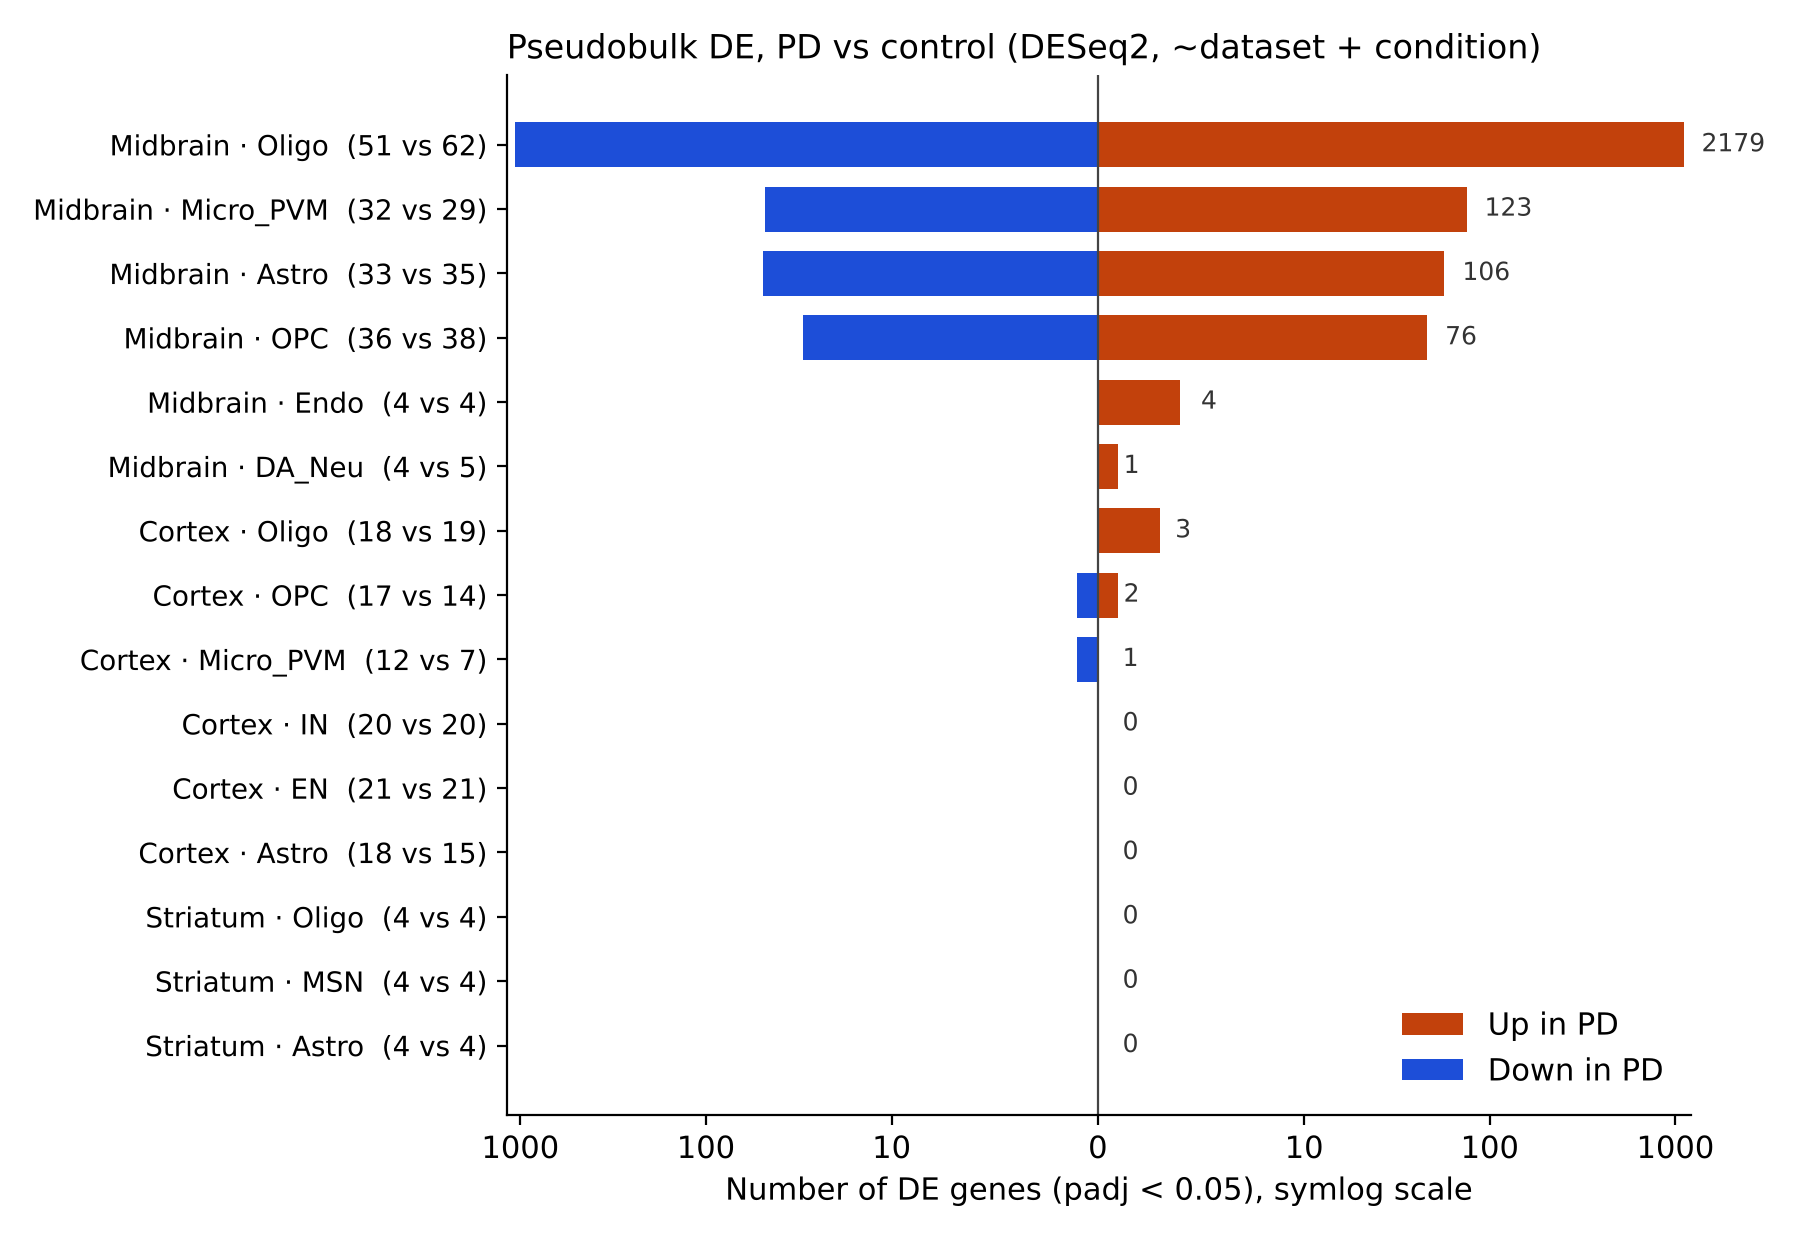

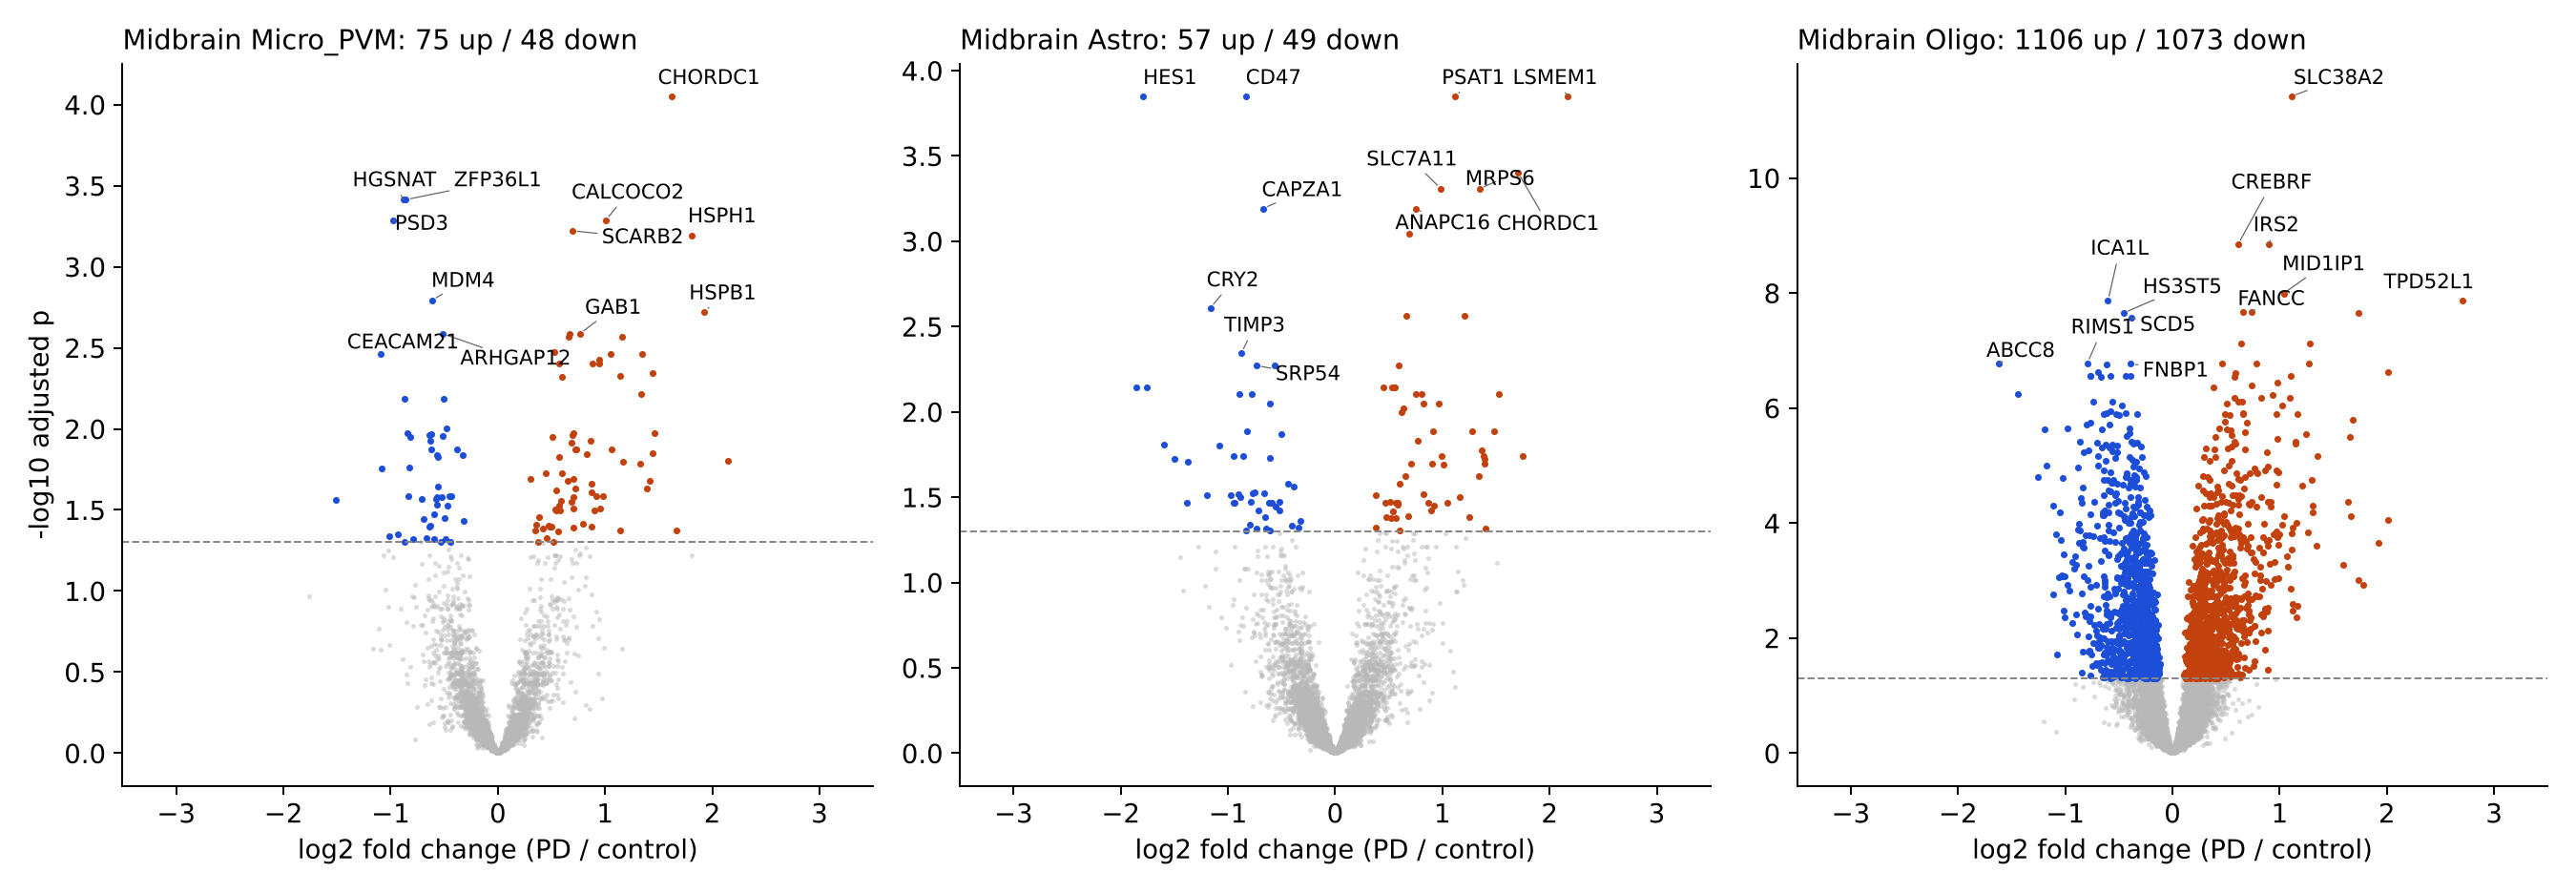

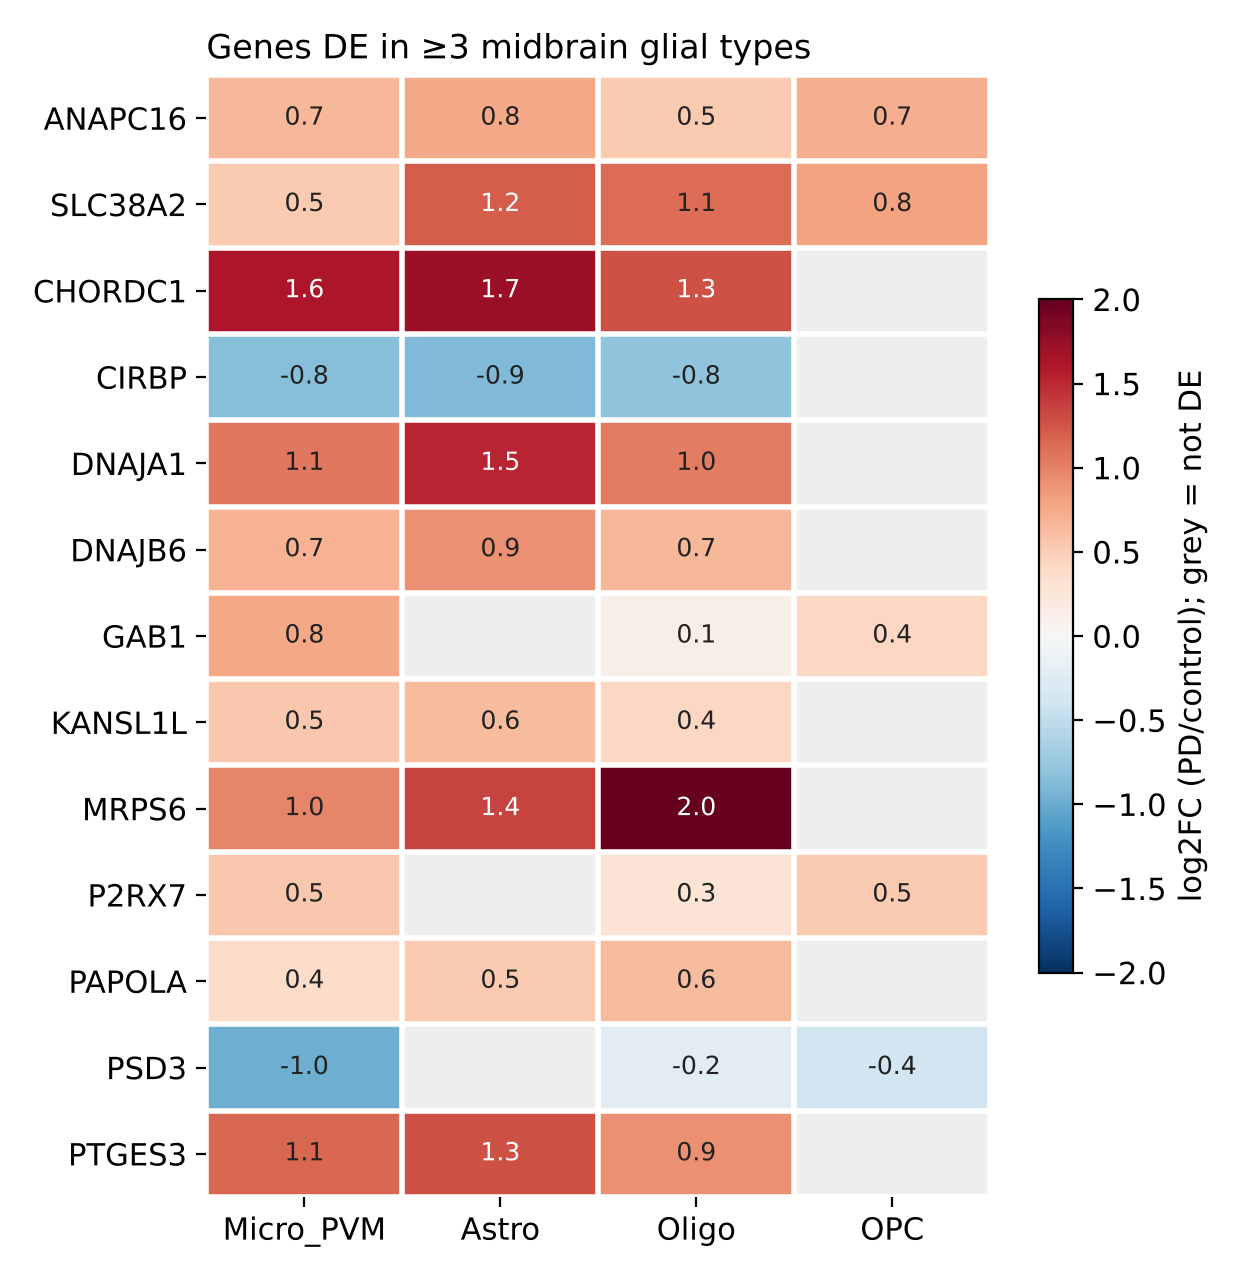

In [3]:
import runpy, warnings; warnings.filterwarnings("ignore")
_ = runpy.run_path("analysis/03_DE_figures.py")
for f in ["de_counts.png", "volcano_midbrain.png", "shared_genes.png"]:
    display(Image("results/pseudobulk/figures/" + f, width=950 if f != "shared_genes.png" else 520))

MD## Top genes per midbrain glial type

In [4]:
for ct in ["Micro_PVM", "Astro", "Oligo", "OPC"]:
    d = pd.read_csv(f"results/pseudobulk/DE_Midbrain_{ct}.csv").dropna(subset=["padj"])
    d = d[d.padj < 0.05]
    print(f"--- Midbrain {ct}: {len(d)} DE genes")
    up = d[d.log2FoldChange > 0].nsmallest(10, "padj"); dn = d[d.log2FoldChange < 0].nsmallest(10, "padj")
    print("  up  :", ", ".join(f"{g} ({l:+.2f})" for g, l in zip(up.gene, up.log2FoldChange)))
    print("  down:", ", ".join(f"{g} ({l:+.2f})" for g, l in zip(dn.gene, dn.log2FoldChange)))

--- Midbrain Micro_PVM: 123 DE genes
  up  : CHORDC1 (+1.62), CALCOCO2 (+1.01), SCARB2 (+0.70), HSPH1 (+1.81), HSPB1 (+1.93), GAB1 (+0.77), OSBPL3 (+0.67), PTGES3 (+1.15), ANAPC16 (+0.66), PTPN12 (+0.53)
  down: ZFP36L1 (-0.86), HGSNAT (-0.88), PSD3 (-0.98), MDM4 (-0.61), ARHGAP12 (-0.51), CEACAM21 (-1.09), PFKFB3 (-0.87), CSF3R (-0.51), GAB3 (-0.48), CIRBP (-0.85)
--- Midbrain Astro: 106 DE genes
  up  : PSAT1 (+1.12), LSMEM1 (+2.17), CHORDC1 (+1.71), MRPS6 (+1.35), SLC7A11 (+0.99), ANAPC16 (+0.75), NPAS2 (+0.69), SLC38A2 (+1.21), SYBU (+0.66), PRRX1 (+0.59)
  down: HES1 (-1.79), CD47 (-0.83), CAPZA1 (-0.67), CRY2 (-1.16), TIMP3 (-0.87), SRP54 (-0.73), AHCYL1 (-0.57), JUNB (-1.85), ADM (-1.76), CIRBP (-0.89)
--- Midbrain Oligo: 2179 DE genes
  up  : SLC38A2 (+1.11), CREBRF (+0.61), IRS2 (+0.90), MID1IP1 (+1.04), TPD52L1 (+2.71), FANCC (+0.74), PNRC1 (+0.66), LUCAT1 (+1.74), PAPOLA (+0.64), CHORDC1 (+1.28)
  down: ICA1L (-0.60), HS3ST5 (-0.46), SCD5 (-0.38), RIMS1 (-0.79), ABCC8 (-1.62

MD**Caution.** Heat-shock chaperones (DNAJA1, DNAJB6, CHORDC1, PTGES3) rise and the cold-shock gene CIRBP falls in every glial type. This shared stress signature may reflect agonal state or post-mortem interval rather than PD. PMI, age and sex are not yet in the model (see README, open issues).